# Diabetes Challenge

Your task today is to **analyze** the Kaggle "Pima Indians Diabetes Database" and to **predict** whether a patient has Diabetes or not.

## Task:
- Load the data from the database. The schema is called `diabetes`. To connect to the database you need to copy the `.env` file from the visualization or hands-on-ml repository into this repo. Explore the database, try to establish what the relationships between the tables are (1-1, 1-N, N-M). Explain to yourself and the group what data do you see and whether it makes sense. What JOINs are appropriate to use and why? 
- Use at least two different classification algorithms we have learned so far to predict Diabetes patients. 
- Discuss before you start with the modeling process which **evaluation metric** you choose and explain why.
- Implement a GridSearchCV or RandomizedSearchCV to tune the hyperparameters of your model.
- **Optional:** If you have time at the end, try to use sklearn's pipline module to encapsulate all the steps into a pipeline.

Don't forget to split your data in train and test set. And analyze your final model on the test data. It might also be necessary to scale your data in order to improve the performance of some of the models.


## Helpful links and advise:
- [sklearn documentation on hyperparameter tuning](https://scikit-learn.org/stable/modules/grid_search.html#grid-search)
- It might be helpful to check some sources on how to deal with imbalanced data. 
    * [8 Tactics to Combat Imbalanced Classes](https://machinelearningmastery.com/tactics-to-combat-imbalanced-classes-in-your-machine-learning-dataset/)
    * [Random-Oversampling/Undersampling](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/)


# Data Description

## Context
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

## Acknowledgements
Smith, J.W., Everhart, J.E., Dickson, W.C., Knowler, W.C., & Johannes, R.S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. In Proceedings of the Symposium on Computer Applications and Medical Care (pp. 261--265). IEEE Computer Society Press.

## About this dataset
The datasets consist of several medical predictor (independent) variables and one target (dependent) variable, Outcome. Independent variables include the number of pregnancies the patient has had, their BMI, insulin level, age, and so on. For the outcome class value 1 is interpreted as "tested positive for diabetes".

|Column Name| Description|
|:------------|:------------|
|Pregnancies|Number of times pregnant|
|Glucose|Plasma glucose concentration a 2 hours in an oral glucose tolerance test|
|BloodPressure|Diastolic blood pressure (mm Hg)|
|SkinThickness|Triceps skin fold thickness (mm)|
|Insulin|2-Hour serum insulin (mu U/ml)|
|BMI|Body mass index (weight in kg/(height in m)^2)|
|DiabetesPedigreeFunction| Diabetes pedigree function|
|Age| Age (years)|
|Outcome|Class variable (0 or 1) |

## Step 1 - Goal and Success Metric

Goal: predict whether a patient has diabetes (`Outcome = 1`) from eight medical measurements.

This is a medical screening task. A **false negative** (a diabetic patient told they are healthy) is much more costly than a **false positive** (a healthy patient sent to a second test). Accuracy treats both errors the same, and recall alone would reward a model that flags everyone.

I therefore select and tune models on the **F2 score** (F-beta with beta = 2), which weights recall twice as much as precision.

In [10]:
import os
import pandas as pd
from sqlalchemy import create_engine
from dotenv import load_dotenv

load_dotenv()
db = create_engine(os.getenv("DB_STRING"))

tables = pd.read_sql("""
SELECT table_name
FROM information_schema.tables
WHERE table_schema = 'diabetes';
""", db)
tables

,table_name
0,blood_metrics
1,patient
2,pedigree_outcome
3,skin


In [11]:
db = create_engine(os.getenv("DB_STRING"), pool_pre_ping=True)

for t in tables["table_name"]:
    with db.connect() as conn:
        df_t = pd.read_sql(f"SELECT * FROM diabetes.{t};", conn)
    print(t, df_t.shape)
    print(list(df_t.columns))
    print("-" * 40)

blood_metrics (1771, 6)
['insulin', 'glucose', 'bloodpressure', 'patientid', 'id', 'measurement_date']
----------------------------------------
patient (768, 4)
['id', 'Age', 'pregnancies', 'bmi']
----------------------------------------
pedigree_outcome (768, 4)
['diabetespedigreefunction', 'outcome', 'patientid', 'id']
----------------------------------------
skin (768, 3)
['skinthickness', 'patientid', 'id']
----------------------------------------


In [12]:
with db.connect() as conn:
    blood = pd.read_sql("SELECT * FROM diabetes.blood_metrics;", conn)

print(blood["patientid"].value_counts().value_counts().sort_index())
print(blood["measurement_date"].value_counts())

count
1    235
2    768
Name: count, dtype: int64
measurement_date
2022-12-13    1003
2022-12-01     768
Name: count, dtype: int64


In [13]:
with db.connect() as conn:
    patient = pd.read_sql("SELECT * FROM diabetes.patient;", conn)

blood_ids = set(blood["patientid"])
patient_ids = set(patient["id"])

print("in blood:", len(blood_ids))
print("in patient:", len(patient_ids))
print("in both:", len(blood_ids & patient_ids))
print("only in blood:", len(blood_ids - patient_ids))
print("only in patient:", len(patient_ids - blood_ids))

in blood: 1003
in patient: 768
in both: 768
only in blood: 235
only in patient: 0


In [14]:
real = blood[blood["patientid"].isin(patient["id"])].copy()
real["measurement_date"] = real["measurement_date"].astype(str)

first_id = patient["id"].iloc[0]
print(real[real["patientid"] == first_id].sort_values("measurement_date"))

cols = ["glucose", "insulin", "bloodpressure"]
d1 = real[real["measurement_date"] == "2022-12-01"].set_index("patientid")[cols]
d2 = real[real["measurement_date"] == "2022-12-13"].set_index("patientid")[cols]
d2 = d2.loc[d1.index]

print((d1 == d2).mean())

     insulin  glucose  bloodpressure  patientid   id measurement_date
768       80      172            117          1  769       2022-12-01
0          0      148             72          1    1       2022-12-13
glucose          0.005208
insulin          0.006510
bloodpressure    0.009115
dtype: float64


In [15]:
with db.connect() as conn:
    po = pd.read_sql("SELECT patientid, outcome FROM diabetes.pedigree_outcome;", conn)

check = real.merge(po, on="patientid")
print(check.groupby(["measurement_date", "outcome"])[["glucose", "insulin", "bloodpressure"]].mean().round(1))

                          glucose  insulin  bloodpressure
measurement_date outcome                                 
2022-12-01       0          104.4     47.6           64.2
                 1           97.5     50.0           60.9
2022-12-13       0          110.0     68.8           68.2
                 1          141.3    100.3           70.8


In [16]:
query = """
SELECT *
FROM diabetes.patient p
LEFT JOIN diabetes.blood_metrics b ON p.id = b.patientid
LEFT JOIN diabetes.skin s ON p.id = s.patientid
LEFT JOIN diabetes.pedigree_outcome po ON p.id = po.patientid
WHERE b.measurement_date = '2022-12-13';
"""

with db.connect() as conn:
    df = pd.read_sql(query, conn)

print(df.shape)
df.head()

(768, 17)


,id,Age,pregnancies,bmi,insulin,glucose,bloodpressure,patientid,id,measurement_date,skinthickness,patientid,id,diabetespedigreefunction,outcome,patientid,id
0,1,50,6,33.6,0,148,72,1,1,2022-12-13,35,1,1,0.627,1,1,1
1,2,31,1,26.6,0,85,66,2,2,2022-12-13,29,2,2,0.351,0,2,2
2,3,32,8,23.3,0,183,64,3,3,2022-12-13,0,3,3,0.672,1,3,3
3,4,21,1,28.1,94,89,66,4,4,2022-12-13,23,4,4,0.167,0,4,4
4,5,33,0,43.1,168,137,40,5,5,2022-12-13,35,5,5,2.288,1,5,5


In [17]:
df = df.drop(columns=["id", "patientid", "measurement_date"])
df = df.rename(columns={
    "pregnancies": "Pregnancies",
    "glucose": "Glucose",
    "bloodpressure": "BloodPressure",
    "skinthickness": "SkinThickness",
    "insulin": "Insulin",
    "bmi": "BMI",
    "diabetespedigreefunction": "DiabetesPedigreeFunction",
    "outcome": "Outcome",
})
print(df.shape)
df.head()

(768, 9)


,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction,Outcome
0,50,6,33.6,0,148,72,35,0.627,1
1,31,1,26.6,0,85,66,29,0.351,0
2,32,8,23.3,0,183,64,0,0.672,1
3,21,1,28.1,94,89,66,23,0.167,0
4,33,0,43.1,168,137,40,35,2.288,1


## Step 2 - Get the Data

The `diabetes` schema has four tables. All of them link to `patient` through `patient.id = patientid`.

| Table | Rows | Relationship to `patient` |
|---|---|---|
| `patient` | 768 | base table (age, pregnancies, BMI) |
| `skin` | 768 | 1-1 |
| `pedigree_outcome` | 768 | 1-1 (contains the target `outcome`) |
| `blood_metrics` | 1771 | 1-N (two measurement dates per patient) |

There are no N-M relationships.

### Findings

- **Orphan rows:** `blood_metrics` contains 1003 distinct `patientid` values, but only 768 exist in `patient`. The 235 extra ids have no age, BMI or outcome, so they are useless for modelling and are dropped by the join.
- **Two measurement dates:** each real patient has one blood row on `2022-12-01` and one on `2022-12-13`. The values differ for more than 99% of patients, so joining without a filter would duplicate every patient (1536 rows) and risk data leakage between train and test.
- **Which date is real?** I tested both dates against the outcome. On `2022-12-13`, diabetic patients have a much higher mean glucose than non-diabetic ones (141.3 vs 110.0), as expected medically. On `2022-12-01` the relation is reversed (97.5 vs 104.4), which suggests synthetic values. The `2022-12-13` values also match the original Kaggle dataset, so I keep only that date.

### Join choice

I use `LEFT JOIN` starting from `patient`, because the patient is the unit of analysis: every registered patient should stay in the data, and a missing measurement would show up as a missing value instead of silently removing the patient. In this data every patient has rows in all tables, so `LEFT JOIN` and `INNER JOIN` return the same 768 rows. Note that the `WHERE` filter on `measurement_date` would turn the `LEFT JOIN` into an `INNER JOIN` anyway.

After the join I drop the key columns (`id`, `patientid`) and `measurement_date`, and rename the columns to the original names. Result: 768 patients, 8 features and the target `Outcome`.

In [18]:
from sklearn.metrics import fbeta_score, make_scorer

f2_scorer = make_scorer(fbeta_score, beta=2)

## Step 3 - Train-Test Split

I split the data before any exploration or cleaning, so that the test set stays unseen and no information from it leaks into the training decisions (for example the medians used for imputation).

- `test_size=0.33`: 514 training rows, 254 test rows.
- `stratify=Outcome`: both parts keep the same class balance (about 65% non-diabetic, 35% diabetic).
- `random_state=42` for a reproducible split.

The classes are imbalanced (65 / 35). I come back to this in the modelling step.

In [20]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df,
    test_size=0.33,
    random_state=42,
    stratify=df["Outcome"],
)
print(df_train.shape, df_test.shape)
print(df_train["Outcome"].value_counts(normalize=True).round(3))
print(df_test["Outcome"].value_counts(normalize=True).round(3))

(514, 9) (254, 9)
Outcome
0    0.652
1    0.348
Name: proportion, dtype: float64
Outcome
0    0.65
1    0.35
Name: proportion, dtype: float64


## Step 4 - Data Exploration

### Hidden missing values

`isnull()` reports no missing values, but `describe()` shows a minimum of 0 in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` and `BMI`. A value of 0 is medically impossible for these measurements, so the zeros are missing values in disguise. (`Pregnancies = 0` is a real value, and `DiabetesPedigreeFunction` and `Age` contain no zeros.)

In [21]:
df_train.describe().round(1)

,Age,Pregnancies,BMI,Insulin,Glucose,BloodPressure,SkinThickness,DiabetesPedigreeFunction,Outcome
count,514.0,514.0,514.0,514.0,514.0,514.0,514.0,514.0,514.0
mean,33.3,3.9,32.2,76.7,120.5,69.3,20.5,0.5,0.3
std,11.6,3.4,7.9,107.5,31.5,18.8,15.6,0.3,0.5
min,21.0,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0
25%,24.0,1.0,27.7,0.0,99.0,62.0,0.0,0.2,0.0
50%,29.5,3.0,32.4,34.0,116.0,72.0,23.0,0.4,0.0
75%,41.0,6.0,36.5,129.8,140.0,80.0,32.0,0.6,1.0
max,81.0,17.0,67.1,744.0,198.0,122.0,60.0,2.3,1.0


In [22]:
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print((df_train[zero_cols] == 0).sum())
print((df_train[zero_cols] == 0).mean().round(3))

Glucose            3
BloodPressure     21
SkinThickness    151
Insulin          249
BMI                8
dtype: int64
Glucose          0.006
BloodPressure    0.041
SkinThickness    0.294
Insulin          0.484
BMI              0.016
dtype: float64


In [23]:
import numpy as np

df_train[zero_cols] = df_train[zero_cols].replace(0, np.nan)

print(df_train.isnull().sum())
print(df_train.corr().round(2)[["Insulin", "SkinThickness"]])

Age                           0
Pregnancies                   0
BMI                           8
Insulin                     249
Glucose                       3
BloodPressure                21
SkinThickness               151
DiabetesPedigreeFunction      0
Outcome                       0
dtype: int64
                          Insulin  SkinThickness
Age                          0.27           0.15
Pregnancies                  0.17           0.14
BMI                          0.23           0.65
Insulin                      1.00           0.26
Glucose                      0.61           0.23
BloodPressure                0.12           0.21
SkinThickness                0.26           1.00
DiabetesPedigreeFunction     0.23           0.11
Outcome                      0.37           0.24


Share of hidden missing values in the training set:

| Column | Missing | Share |
|---|---|---|
| Glucose | 3 | 0.6% |
| BMI | 8 | 1.6% |
| BloodPressure | 21 | 4.1% |
| SkinThickness | 151 | 29.4% |
| Insulin | 249 | 48.4% |

**Decision:**

- `Insulin` and `SkinThickness` are dropped. Imputing almost half of a column with one constant would create a large block of artificial values. Most of their information is also carried by other features: `Insulin` correlates 0.61 with `Glucose`, and `SkinThickness` correlates 0.65 with `BMI`. (Trade-off: `Insulin` still correlates 0.37 with `Outcome`, so some information is lost. I test this later.)
- `Glucose`, `BloodPressure` and `BMI` have few missing values, which I fill with the **training-set median** (116.0, 72.0 and 32.4).
- The test set gets exactly the same treatment with the **training** medians, so no information from the test set is used.

In [24]:
df_train = df_train.drop(columns=["Insulin", "SkinThickness"])

fill_cols = ["Glucose", "BloodPressure", "BMI"]
medians = df_train[fill_cols].median()
print(medians)

df_train[fill_cols] = df_train[fill_cols].fillna(medians)
print(df_train.isnull().sum().sum())

Glucose          116.0
BloodPressure     72.0
BMI               32.4
dtype: float64
0


In [25]:
df_test[zero_cols] = df_test[zero_cols].replace(0, np.nan)
df_test = df_test.drop(columns=["Insulin", "SkinThickness"])
df_test[fill_cols] = df_test[fill_cols].fillna(medians)

print(df_test.isnull().sum().sum())
print(df_train.shape, df_test.shape)

0
(514, 7) (254, 7)


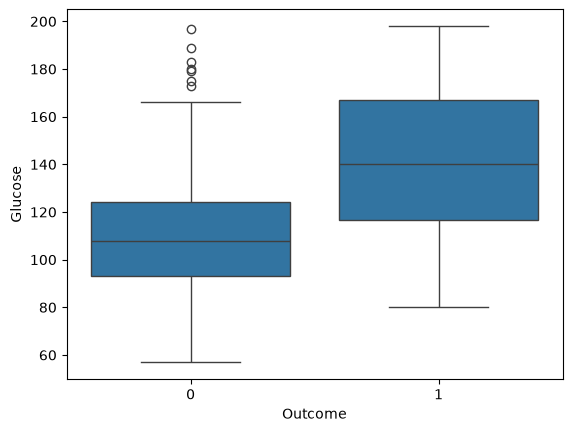

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df_train, x="Outcome", y="Glucose")
plt.show()

In [27]:
from sklearn.metrics import recall_score, precision_score

for cut in [120, 130]:
    y_pred = (df_train["Glucose"] > cut).astype(int)
    print(cut,
          "recall:", round(recall_score(df_train["Outcome"], y_pred), 3),
          "precision:", round(precision_score(df_train["Outcome"], y_pred), 3),
          "F2:", round(fbeta_score(df_train["Outcome"], y_pred, beta=2), 3))

120 recall: 0.698 precision: 0.553 F2: 0.663
130 recall: 0.598 precision: 0.656 F2: 0.609


### Baseline Model

Before training any model I define a simple rule as a benchmark: **predict diabetes if `Glucose > 120`**.

The boxplot shows that most diabetic patients lie above about 117 and most non-diabetic patients below about 124, so the cut-off should sit between the two boxes. I compared two cut-offs on the **training** set (the test set stays untouched):

| Cut-off | Recall | Precision | F2 |
|---|---|---|---|
| 120 | 0.698 | 0.553 | **0.663** |
| 130 | 0.598 | 0.656 | 0.609 |

The lower cut-off catches more diabetic patients at the cost of more false alarms, which is the trade-off F2 rewards. Any real model has to beat **F2 = 0.663**.

In [28]:
X_train = df_train.drop(columns=["Outcome"])
y_train = df_train["Outcome"]
X_test = df_test.drop(columns=["Outcome"])
y_test = df_test["Outcome"]

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(514, 6) (514,) (254, 6) (254,)


In [29]:
from imblearn.over_sampling import SMOTE

X_demo, y_demo = SMOTE(random_state=42).fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_demo.value_counts())

Outcome
0    335
1    179
Name: count, dtype: int64
Outcome
0    335
1    335
Name: count, dtype: int64


## Step 5 - Feature Engineering

### Features and target

After dropping `Insulin` and `SkinThickness`, six features remain: `Age`, `Pregnancies`, `BMI`, `Glucose`, `BloodPressure` and `DiabetesPedigreeFunction`.

### Class imbalance

The training set has 335 non-diabetic and 179 diabetic patients. A model trained on this can lean towards predicting "healthy", which means more false negatives, the error we care about most.

I use **SMOTE** (Synthetic Minority Over-sampling Technique): it creates synthetic diabetic patients between real neighbouring diabetic patients until both classes have 335 rows.

To avoid data leakage, SMOTE is placed **inside an `imblearn` Pipeline**:

1. `MinMaxScaler`: first, because SMOTE finds neighbours by distance, and unscaled features like `Glucose` would dominate the distance.
2. `SMOTE`: runs only during `fit`, on the training part of each cross-validation fold. The validation folds and the test set keep their real class balance.
3. The model.

In [30]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

def make_pipe(model):
    return Pipeline([
        ("scaler", MinMaxScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model),
    ])

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(random_state=42),
    "HistGB": HistGradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    scores = cross_validate(
        make_pipe(model), X_train, y_train,
        cv=cv, scoring=f2_scorer, return_train_score=True,
    )
    print(f"{name:13s} train F2: {scores['train_score'].mean():.3f}   "
          f"val F2: {scores['test_score'].mean():.3f} +/- {scores['test_score'].std():.3f}")

LogReg        train F2: 0.705   val F2: 0.697 +/- 0.033
RandomForest  train F2: 1.000   val F2: 0.661 +/- 0.043
HistGB        train F2: 1.000   val F2: 0.667 +/- 0.059


## Steps 6 to 8 - Model Comparison and Tuning

I compare three model families, each inside the same leakage-safe pipeline (`MinMaxScaler` -> `SMOTE` -> model), with stratified 5-fold cross-validation on the training set and F2 as the score.

| Model (defaults) | Train F2 | Validation F2 |
|---|---|---|
| Logistic Regression | 0.705 | **0.697** +/- 0.033 |
| Random Forest | 1.000 | 0.661 +/- 0.043 |
| HistGradientBoosting | 1.000 | 0.667 +/- 0.059 |
| Baseline (`Glucose > 120`) | | 0.663 |

- Random Forest and HistGradientBoosting memorise the training folds (train F2 = 1.0) but do no better than the simple glucose rule on validation: clear **overfitting**. SMOTE may add to this, since synthetic patients sit right next to real ones and are easy to memorise.
- Logistic Regression has almost no gap between train and validation and scores best, although its lead over the baseline is only about one standard deviation.

Next I tune the models to restrain overfitting.

In [33]:
from sklearn.model_selection import GridSearchCV

rf_grid = {
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
}

rf_gs = GridSearchCV(
    make_pipe(RandomForestClassifier(random_state=42)),
    rf_grid, cv=cv, scoring=f2_scorer,
    return_train_score=True, n_jobs=-1,
)
rf_gs.fit(X_train, y_train)

print("best params:", rf_gs.best_params_)
print("best val F2:", round(rf_gs.best_score_, 3))

best params: {'model__max_depth': 3, 'model__min_samples_leaf': 10}
best val F2: 0.713


In [34]:
best = rf_gs.best_index_
res = rf_gs.cv_results_

print("train F2:", round(res["mean_train_score"][best], 3))
print("val F2:  ", round(res["mean_test_score"][best], 3),
      "+/-", round(res["std_test_score"][best], 3))

train F2: 0.766
val F2:   0.713 +/- 0.032


In [35]:
import numpy as np

lr_grid = {
    "model__C": np.logspace(-3, 2, 6),
    "model__l1_ratio": [0, 0.5, 1],
}

lr_gs = GridSearchCV(
    make_pipe(LogisticRegression(solver="saga", max_iter=5000)),
    lr_grid, cv=cv, scoring=f2_scorer,
    return_train_score=True, n_jobs=-1,
)
lr_gs.fit(X_train, y_train)

best = lr_gs.best_index_
res = lr_gs.cv_results_
print("best params:", lr_gs.best_params_)
print("train F2:", round(res["mean_train_score"][best], 3))
print("val F2:  ", round(res["mean_test_score"][best], 3),
      "+/-", round(res["std_test_score"][best], 3))

best params: {'model__C': np.float64(1.0), 'model__l1_ratio': 0}
train F2: 0.705
val F2:   0.698 +/- 0.033


In [36]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint

hgb_dist = {
    "model__learning_rate": loguniform(0.01, 0.5),
    "model__max_depth": [2, 3, 4, None],
    "model__max_leaf_nodes": randint(4, 32),
    "model__min_samples_leaf": randint(5, 50),
}

hgb_rs = RandomizedSearchCV(
    make_pipe(HistGradientBoostingClassifier(random_state=42)),
    hgb_dist, n_iter=40, cv=cv, scoring=f2_scorer,
    return_train_score=True, n_jobs=-1, random_state=42,
)
hgb_rs.fit(X_train, y_train)

best = hgb_rs.best_index_
res = hgb_rs.cv_results_
print("best params:", hgb_rs.best_params_)
print("train F2:", round(res["mean_train_score"][best], 3))
print("val F2:  ", round(res["mean_test_score"][best], 3),
      "+/-", round(res["std_test_score"][best], 3))

best params: {'model__learning_rate': np.float64(0.043284502212938815), 'model__max_depth': 2, 'model__max_leaf_nodes': 18, 'model__min_samples_leaf': 47}
train F2: 0.778
val F2:   0.695 +/- 0.03


### Hyperparameter Tuning

| Model | Search | Best parameters | Train F2 | Validation F2 |
|---|---|---|---|---|
| Logistic Regression | Grid (18 combos) | `C = 1.0`, `l1_ratio = 0` | 0.705 | 0.698 +/- 0.033 |
| Random Forest | Grid (20 combos) | `max_depth = 3`, `min_samples_leaf = 10` | 0.766 | 0.713 +/- 0.032 |
| HistGradientBoosting | Randomized (40 combos) | `max_depth = 2`, `min_samples_leaf = 47`, `learning_rate = 0.043` | 0.778 | 0.695 +/- 0.030 |
| Baseline (`Glucose > 120`) | | | | 0.663 |

**What tuning changed:**

- **Random Forest:** restricting tree depth removed most of the overfitting (train-validation gap from 0.34 to 0.05) and raised validation F2 from 0.661 to 0.713.
- **HistGradientBoosting:** the search also picked very shallow trees with large leaves. With `max_depth = 2` a tree has at most 4 leaves, so `max_leaf_nodes` has no effect. `min_samples_leaf` ended close to the upper bound of the search range.
- **Logistic Regression:** the best combination is the default (`C = 1`, L2 penalty). The model did not overfit, so there was nothing for tuning to fix.

**Model choice (made before looking at the test set):**

All three tuned models are within one standard deviation of each other (largest difference 0.018 vs a typical std of 0.03), so the differences are noise. I choose **Logistic Regression** as the final model: it has the smallest train-validation gap, it is the simplest model, and its coefficients can be read by a doctor. The other two models are reported on the test set for comparison only.

In [37]:
from sklearn.metrics import classification_report, confusion_matrix

final_model = lr_gs.best_estimator_
y_pred = final_model.predict(X_test)

print("test F2:", round(fbeta_score(y_test, y_pred, beta=2), 3))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

test F2: 0.684
              precision    recall  f1-score   support

           0       0.83      0.79      0.81       165
           1       0.64      0.70      0.67        89

    accuracy                           0.76       254
   macro avg       0.73      0.74      0.74       254
weighted avg       0.76      0.76      0.76       254

[[130  35]
 [ 27  62]]


In [38]:
from sklearn.metrics import roc_auc_score, f1_score, recall_score

tuned = {"LogReg": lr_gs, "RandomForest": rf_gs, "HistGB": hgb_rs}

for name, search in tuned.items():
    m = search.best_estimator_
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    print(f"{name:13s} AUC: {roc_auc_score(y_test, proba):.2f}  "
          f"AUC from labels: {roc_auc_score(y_test, pred):.2f}  "
          f"F1: {f1_score(y_test, pred):.2f}  recall: {recall_score(y_test, pred):.2f}")

LogReg        AUC: 0.84  AUC from labels: 0.74  F1: 0.67  recall: 0.70
RandomForest  AUC: 0.85  AUC from labels: 0.76  F1: 0.69  recall: 0.80
HistGB        AUC: 0.84  AUC from labels: 0.76  F1: 0.69  recall: 0.78


result
TN    130
TP     62
FP     35
FN     27
Name: count, dtype: int64


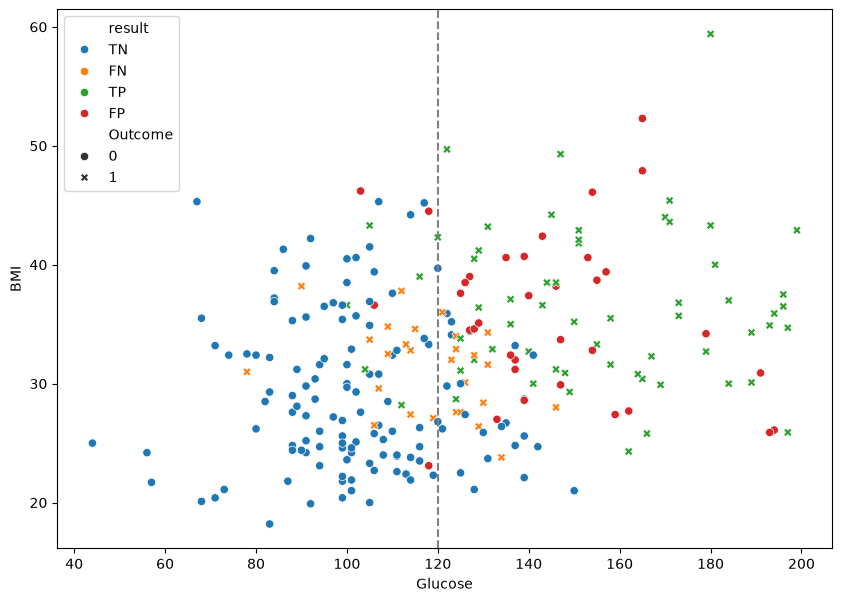

        Glucose   BMI   Age
result                     
FN        121.0  32.0  31.0
FP        140.0  35.1  34.0
TN        101.0  27.5  25.0
TP        151.0  35.6  38.0


In [40]:
errors = df_test.copy()
errors["result"] = np.select(
    [(y_pred == 1) & (y_test == 1),
     (y_pred == 0) & (y_test == 0),
     (y_pred == 1) & (y_test == 0),
     (y_pred == 0) & (y_test == 1)],
    ["TP", "TN", "FP", "FN"],
    default="?",
)
print(errors["result"].value_counts())

plt.figure(figsize=(10, 7))
sns.scatterplot(data=errors, x="Glucose", y="BMI", hue="result", style="Outcome")
plt.axvline(120, color="grey", linestyle="--")
plt.show()

print(errors.groupby("result")[["Glucose", "BMI", "Age"]].median())

## Step 9 - Test Score

The final model (Logistic Regression, chosen before looking at the test set) on the 254 test patients:

| | Predicted healthy | Predicted diabetic |
|---|---|---|
| **Actually healthy** | 130 (TN) | 35 (FP) |
| **Actually diabetic** | 27 (FN) | 62 (TP) |

- **Test F2 = 0.684**, close to the cross-validation estimate of 0.698 +/- 0.033, so the model generalises as expected.
- Recall 0.70 (62 of 89 diabetic patients caught), precision 0.64, accuracy 0.76, ROC AUC 0.84.

For comparison only (not used for model selection):

| Model | Test ROC AUC | Test F1 | Test Recall |
|---|---|---|---|
| Logistic Regression (final) | 0.84 | 0.67 | 0.70 |
| Random Forest | 0.85 | 0.69 | 0.80 |
| HistGradientBoosting | 0.84 | 0.69 | 0.78 |

The tree models reach a higher recall on this test set, but switching models after seeing test scores would turn the test set into a validation set. A fair way to raise recall is to lower the decision threshold, chosen on the training data.

Note: ROC AUC must be computed from `predict_proba`, not from the 0/1 predictions. From labels, the same Logistic Regression scores only 0.74.

### Error Analysis

| Group | Median Glucose | Median BMI | Median Age |
|---|---|---|---|
| TN | 101 | 27.5 | 25 |
| FN | 121 | 32.0 | 31 |
| FP | 140 | 35.1 | 34 |
| TP | 151 | 35.6 | 38 |

- The missed diabetic patients (FN) sit in the "grey zone" around a glucose of 120, where healthy and diabetic patients overlap. They are younger and leaner than the caught ones, possibly early or mild cases.
- The false alarms (FP) have high glucose and BMI. Even without diabetes they are high-risk patients, so a follow-up test is not wasted.
- The model's decision is driven mainly by glucose, close to the baseline rule, but it beats the baseline by combining glucose with BMI, age and the pedigree function.

## Conclusion

- **Data:** the SQL data contained two traps, 235 orphan blood records and a second set of synthetic measurements. Testing glucose against the outcome identified the real measurement date.
- **Cleaning:** hidden zeros were treated as missing values; `Insulin` and `SkinThickness` were dropped because about half / a third of their values were missing and their information is largely carried by `Glucose` and `BMI`.
- **Modelling:** with F2 as the metric and SMOTE inside the pipeline, all tuned models beat the glucose baseline (0.663), but Logistic Regression, Random Forest and HistGradientBoosting are within noise of each other (0.695 to 0.713).
- **Final model:** Logistic Regression, chosen before the test evaluation for its stability and interpretability. Test F2 = 0.684, recall = 0.70, ROC AUC = 0.84.
- **Lesson:** on a small dataset, tuning helps where there is overfitting to fix (Random Forest: gap from 0.34 to 0.05), and more complex models are not automatically better.

### Next steps

- Choose a lower decision threshold on the training data (via cross-validated probabilities) to raise recall.
- Test whether a "was insulin measured?" indicator carries information, instead of dropping `Insulin` completely.
- Step 10, deployment and monitoring, is out of scope for this challenge.